# ShopSense AI — Predicting Purchase Intent

**One notebook, four connected stages:** A. Explore the data → B. Prepare the features → C. Compare models → D. Explain and use a frozen model.

**My question:** Can I distinguish sessions that end in a purchase (`Revenue=True`) from sessions that do not, using summaries of browsing behavior?

I treat this as an **offline, end-of-session benchmark**. The dataset does not prove that these features are available early enough to make real-time predictions. My goal is a reproducible comparison and an understandable model, not a claim of increased sales.

**My success criteria:** (1) clean, traceable data and leakage-safe partitions; (2) beat a majority/prior dummy baseline on validation **Average Precision (AP)**; (3) show precision, recall, F1 and threshold tradeoffs; (4) explain the model and run raw-input predictions; (5) freeze the approach before one final test evaluation.

**Sources:** [Kaggle mirror](https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset) · [Original UCI data](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) · [UCI DOI](https://doi.org/10.24432/C5F88Q) (Sakar & Kastro, 2018; CC BY 4.0). I keep the original attribution. No claim of independent dataset creation.

## A — Data exploration and quality checks

I will load the named dataset, check whether it matches its documentation, and separate the data **before** target-related exploratory charts. Whole-file checks are limited to integrity, schema, and headline class counts. I will use the **training** partition for detailed comparisons that might influence model choices.

**To run:** start from the repository root, install `requirements.txt`, then use **Run all**. In Colab, upload this notebook or open it from GitHub. The first cells create `data/`, `outputs/`, and `models/` wherever the notebook starts; in Colab this is usually `/content`. Downloads require an internet connection. If downloaded data are present locally, I will reuse them and record their checksum.

In [1]:

%pip install -q scikit-learn==1.8.0


In [2]:
from pathlib import Path
import hashlib
import json
import platform
import shutil
import urllib.request
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.13.16
pandas: 2.2.3 | scikit-learn: 1.8.0


### Paths and source preference

I prefer the named Kaggle mirror if `kagglehub` is installed and permits access. If it is unavailable, I use the **original UCI CSV**, not a different dataset. The cell reports which route succeeded. The exact Kaggle revision and its separate listing terms have **not** been verified here; UCI publishes the originating dataset with CC BY 4.0. I do not store Kaggle credentials in this notebook.

In [3]:
# EDITABLE: point this at an existing CSV to skip all downloads.
repo_root = Path.cwd().resolve()
if repo_root.name == 'notebooks':
    repo_root = repo_root.parent
for folder in ['data', 'outputs', 'models']:
    (repo_root / folder).mkdir(parents=True, exist_ok=True)

dataset_path = repo_root / 'data' / 'online_shoppers_intention.csv'
uci_csv_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv'
kaggle_dataset_slug = 'imakash3011/online-shoppers-purchasing-intention-dataset'
source_used = 'Existing local CSV (provenance must be checked separately)'

if not dataset_path.exists():
    kaggle_error = None
    try:
        import kagglehub
        cache_dir = Path(kagglehub.dataset_download(kaggle_dataset_slug))
        choices = list(cache_dir.rglob('online_shoppers_intention.csv'))
        if not choices:
            raise FileNotFoundError('Kaggle downloaded, but expected CSV was not found')
        shutil.copy2(choices[0], dataset_path)
        source_used = f'Kaggle mirror: {kaggle_dataset_slug}'
    except (Exception) as exc:
        kaggle_error = str(exc)
        print('Kaggle route unavailable:', kaggle_error[:220])
        print('Trying UCI original URL instead...')
        try:
            urllib.request.urlretrieve(uci_csv_url, dataset_path)
            source_used = f'Original UCI: {uci_csv_url}'
        except Exception as uci_error:
            raise RuntimeError(
                'The dataset could not be downloaded in this runtime. '
                'Download online_shoppers_intention.csv manually from UCI/Kaggle '
                'into data/ and rerun this cell. UCI error: '
                + str(uci_error)
            ) from uci_error

file_checksum = hashlib.sha256(dataset_path.read_bytes()).hexdigest()
# A local provenance record is only trusted for the exact matching checksum.
source_manifest = repo_root / 'data' / 'source.json'
if dataset_path.exists() and source_manifest.exists():
    known_source = json.loads(source_manifest.read_text())
    if known_source.get('sha256') == file_checksum:
        source_used = known_source['source']
    else:
        print('Existing provenance record has a different checksum; not reusing it.')
print('Source:', source_used)
print('File:', dataset_path.name)
print('Size:', f'{dataset_path.stat().st_size:,}', 'bytes')
print('SHA-256:', file_checksum)

Source: Existing local CSV (provenance must be checked separately)
File: online_shoppers_intention.csv
Size: 1,072,064 bytes
SHA-256: a7e2714f884a221e95822830fe8e4400e9365d5e5af7c619f3fc6c9343254ad6


### Inspect the actual file

UCI describes 12,330 sessions, 17 predictors, and a Boolean `Revenue` label. Those are **source descriptions**, not my measured results until the cells below run. I will validate the downloaded copy rather than forcing it to match the description.

In [4]:
df = pd.read_csv(dataset_path)
print('Shape:', df.shape)
display(df.head())

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
print('Dtypes:')
display(df.dtypes.to_frame('dtype'))
print('Missing values:')
display(df.isna().sum().to_frame('missing_count'))

Dtypes:


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


Missing values:


,missing_count
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [6]:
expected_columns = [
    'Administrative', 'Administrative_Duration', 'Informational',
    'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
    'OperatingSystems', 'Browser', 'Region', 'TrafficType',
    'VisitorType', 'Weekend', 'Revenue',
]
missing_columns = sorted(set(expected_columns) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(expected_columns))
assert not missing_columns and not extra_columns, (missing_columns, extra_columns)
assert df.columns.is_unique, 'Repeated column names'
assert df.notna().all().all(), 'Unexpected missing values: investigate before modeling'

# Accept the two genuine CSV encodings of a Boolean outcome, but not invented target labels.
raw_target = df['Revenue'].astype(str).str.strip().str.lower()
assert set(raw_target.unique()) == {'true', 'false'}, raw_target.value_counts().to_dict()
df['Revenue'] = raw_target.eq('true').astype(int)
raw_weekend = df['Weekend'].astype(str).str.strip().str.lower()
assert set(raw_weekend.unique()).issubset({'true', 'false'})
df['Weekend'] = raw_weekend.eq('true')

numeric_source = ['Administrative', 'Administrative_Duration', 'Informational',
                  'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                  'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
for col in numeric_source + ['OperatingSystems', 'Browser', 'Region', 'TrafficType']:
    df[col] = pd.to_numeric(df[col], errors='raise')
assert np.isfinite(df[numeric_source + ['OperatingSystems', 'Browser', 'Region', 'TrafficType']].to_numpy()).all()
print('Revenue: 0=no purchase, 1=purchase')
display(df['Revenue'].value_counts().rename(index={0:'No purchase',1:'Purchase'}).to_frame('sessions'))

Revenue: 0=no purchase, 1=purchase


,sessions
Revenue,
No purchase,10422
Purchase,1908


In [7]:
# Integrity checks: do not silently delete surprising observations.
counts = ['Administrative', 'Informational', 'ProductRelated']
durations = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']
rates = ['BounceRates', 'ExitRates', 'SpecialDay']
checks = {
    'negative page counts': int(df[counts].lt(0).sum().sum()),
    'non-integer page counts': int((df[counts] % 1 != 0).sum().sum()),
    'negative durations': int(df[durations].lt(0).sum().sum()),
    'negative PageValues': int(df['PageValues'].lt(0).sum()),
    'rates outside [0, 1]': int(((df[rates] < 0) | (df[rates] > 1)).sum().sum()),
    'non-positive numeric category codes': int((df[['OperatingSystems', 'Browser', 'Region', 'TrafficType']] <= 0).sum().sum()),
    'exact duplicate rows': int(df.duplicated().sum()),
}
display(pd.Series(checks, name='count').to_frame())
for col in ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']:
    print(col, sorted(df[col].dropna().unique().tolist(), key=str))
assert all(checks[k] == 0 for k in list(checks)[:6]), 'Integrity issue: inspect, do not silently fix'
assert df['Month'].isin(['Jan','Feb','Mar','Apr','May','June','Jul','Aug','Sep','Oct','Nov','Dec']).all(), 'Unexpected Month category'
assert df['VisitorType'].isin(['Returning_Visitor','New_Visitor','Other']).all(), 'Unexpected VisitorType'

,count
negative page counts,0
non-integer page counts,0
negative durations,0
negative PageValues,0
"rates outside [0, 1]",0
non-positive numeric category codes,0
exact duplicate rows,125


Month ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
VisitorType ['New_Visitor', 'Other', 'Returning_Visitor']
Weekend [False, True]
OperatingSystems [1, 2, 3, 4, 5, 6, 7, 8]
Browser [1, 10, 11, 12, 13, 2, 3, 4, 5, 6, 7, 8, 9]
Region [1, 2, 3, 4, 5, 6, 7, 8, 9]
TrafficType [1, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 2, 20, 3, 4, 5, 6, 7, 8, 9]


### Duplicate investigation and safe separation

Two rows can have identical recorded features but different labels; without a session ID, I cannot prove they are actually the same session. Deleting them just to make the data unique would be a strong assumption. I will **keep all observations** and group identical predictor fingerprints into the same partition. This also prevents identical inputs (even when their labels conflict) from appearing on both sides of an evaluation boundary.

Because there are groups, I use a reproducible **7-fold stratified-group partition**: five folds train, one validation, one test. The *target* allocation is approximately 71/14/14 rather than precisely 70/15/15. I will inspect the **actual** sizes and prevalences. These are not temporal splits.

In [8]:
# EDITABLE: changes to the random seed require rerunning every subsequent cell.
random_state = 42

primary_columns = [c for c in df.columns if c not in ['Revenue', 'PageValues']]
# Hashing raw primary predictors keeps all identical primary inputs together.
features_for_grouping = df[primary_columns].copy()
group_ids = pd.util.hash_pandas_object(features_for_grouping, index=False)
print('Unique primary feature vectors:', group_ids.nunique())
print('Duplicated primary feature vectors:', int(group_ids.duplicated().sum()))

group_label_counts = df.groupby(group_ids)['Revenue'].nunique()
print('Primary feature fingerprints with conflicting targets:', int(group_label_counts.gt(1).sum()))
print('Decision: retain all records; use group-aware partitioning.')

Unique primary feature vectors: 12205
Duplicated primary feature vectors: 125
Primary feature fingerprints with conflicting targets: 0
Decision: retain all records; use group-aware partitioning.


In [9]:
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=random_state)
fold_id = np.full(len(df), -1, dtype=int)
for fold, (_, fold_indices) in enumerate(splitter.split(df[primary_columns], df['Revenue'], groups=group_ids)):
    fold_id[fold_indices] = fold
assert (fold_id >= 0).all()

train_mask = fold_id >= 2
valid_mask = fold_id == 1
test_mask = fold_id == 0
X_train = df.loc[train_mask, primary_columns].copy()
y_train = df.loc[train_mask, 'Revenue'].copy()
X_valid = df.loc[valid_mask, primary_columns].copy()
y_valid = df.loc[valid_mask, 'Revenue'].copy()
X_test = df.loc[test_mask, primary_columns].copy()
y_test = df.loc[test_mask, 'Revenue'].copy()
groups_train = group_ids.loc[train_mask]

split_report = pd.DataFrame({
    'partition': ['train','validation','test'],
    'sessions': [len(y_train),len(y_valid),len(y_test)],
    'purchase_rate': [y_train.mean(),y_valid.mean(),y_test.mean()],
})
split_report['share_of_data'] = split_report['sessions'] / len(df)
display(split_report.style.format({'purchase_rate':'{:.2%}','share_of_data':'{:.2%}'}))
assert len(X_train) + len(X_valid) + len(X_test) == len(df)
assert len(set(groups_train) & set(group_ids.loc[valid_mask])) == 0
assert len(set(groups_train) & set(group_ids.loc[test_mask])) == 0
assert len(set(group_ids.loc[valid_mask]) & set(group_ids.loc[test_mask])) == 0
assert all(s.nunique() == 2 for s in [y_train,y_valid,y_test]), 'Both classes needed in every partition'

,partition,sessions,purchase_rate,share_of_data
0,train,8807,15.48%,71.43%
1,validation,1762,15.49%,14.29%
2,test,1761,15.45%,14.28%


### Training-only business exploration

I will ask four questions using `train` only. Overall purchase frequency is an integrity check; the following comparisons are for learning patterns, not causal conclusions.

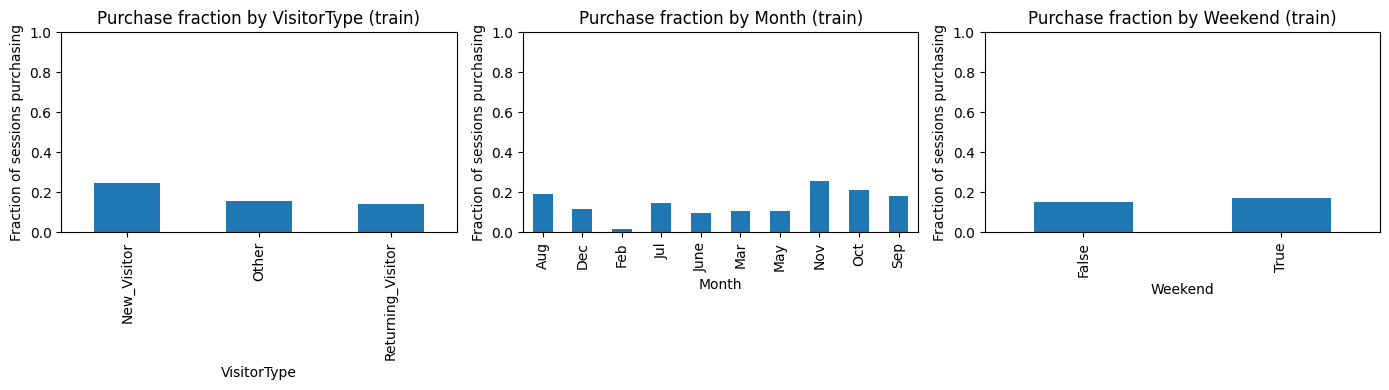

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, feature in zip(axes, ['VisitorType', 'Month', 'Weekend']):
    chart_data = pd.DataFrame({feature:X_train[feature], 'Revenue':y_train}).groupby(feature, observed=True)['Revenue'].agg(['mean','size'])
    chart_data['mean'].sort_index().plot.bar(ax=ax)
    ax.set_title(f'Purchase fraction by {feature} (train)')
    ax.set_ylabel('Fraction of sessions purchasing')
    ax.set_xlabel(feature)
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(repo_root/'outputs'/'training_purchase_rates.png', dpi=145)
plt.show()

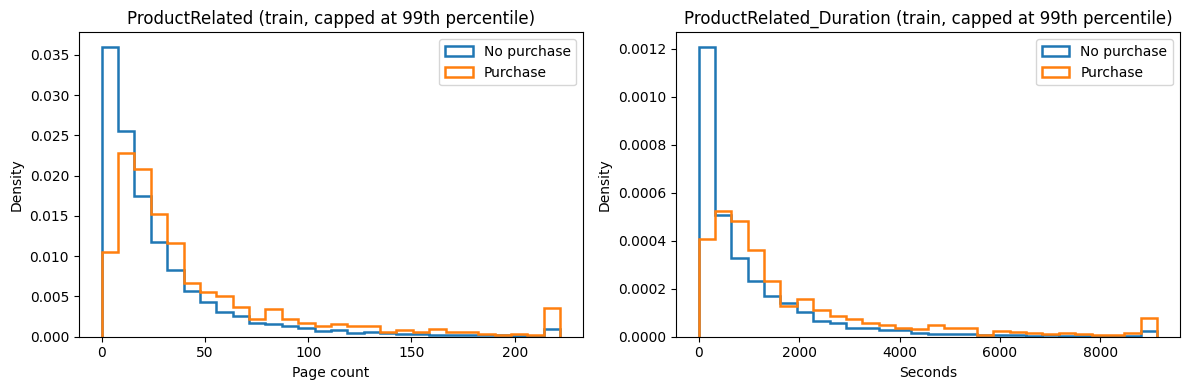

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, ['ProductRelated', 'ProductRelated_Duration']):
    for label in [0, 1]:
        values = X_train.loc[y_train==label,feature].clip(upper=X_train[feature].quantile(.99))
        ax.hist(values, bins=28, density=True, histtype='step', linewidth=1.8,
                label=('No purchase' if label==0 else 'Purchase'))
    ax.set_title(f'{feature} (train, capped at 99th percentile)')
    ax.set_xlabel('Page count' if feature=='ProductRelated' else 'Seconds')
    ax.set_ylabel('Density')
    ax.legend()
plt.tight_layout()
plt.savefig(repo_root/'outputs'/'training_page_activity.png', dpi=145)
plt.show()

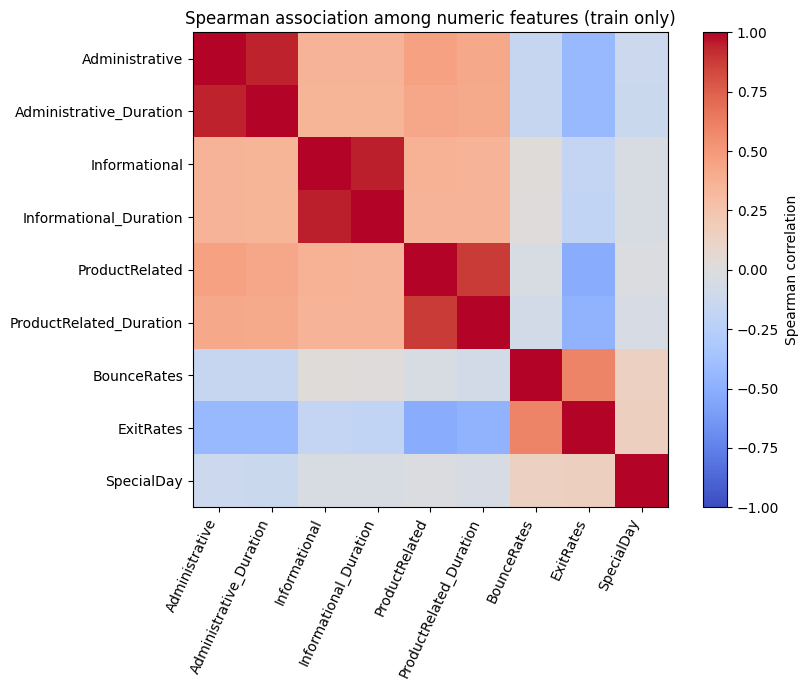

In [12]:
train_numeric = ['Administrative','Administrative_Duration','Informational',
                 'Informational_Duration','ProductRelated','ProductRelated_Duration',
                 'BounceRates','ExitRates','SpecialDay']
correlation = X_train[train_numeric].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(correlation.to_numpy(), vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(correlation.columns)), correlation.columns,rotation=65,ha='right')
ax.set_yticks(range(len(correlation.index)), correlation.index)
ax.set_title('Spearman association among numeric features (train only)')
fig.colorbar(im,ax=ax,label='Spearman correlation')
plt.tight_layout()
plt.savefig(repo_root/'outputs'/'training_correlations.png', dpi=145)
plt.show()

In [13]:
def describe_purchase_patterns(X_part, y_part):
    summary = pd.concat([X_part, y_part.rename('Revenue')], axis=1)
    for feature in ['VisitorType', 'Month', 'Weekend']:
        rate = summary.groupby(feature, observed=True)['Revenue'].agg(['mean','count'])
        highest = rate.loc[rate['mean'].idxmax()]
        print(f'{feature}: highest observed purchase fraction = {rate["mean"].max():.1%}, '
              f'group size = {int(highest["count"])}. Observational, not causal.')

describe_purchase_patterns(X_train,y_train)

VisitorType: highest observed purchase fraction = 24.8%, group size = 1204. Observational, not causal.
Month: highest observed purchase fraction = 25.8%, group size = 2109. Observational, not causal.
Weekend: highest observed purchase fraction = 17.0%, group size = 2047. Observational, not causal.


In [14]:
# My interpretation is computed from the training set, not copied from test results.
train_pattern = pd.DataFrame({'Month':X_train['Month'],'Revenue':y_train}).groupby('Month')['Revenue'].mean()
display(Markdown(
    f'**My training observation:** purchases are {y_train.mean():.1%} of training sessions. '
    f'Month-specific fractions range from {train_pattern.min():.1%} to {train_pattern.max():.1%}. '
    'I will keep `Month` categorical. These differences may reflect seasonality or how sessions were sampled, '
    'not a causal effect or proof of future stability.'
))

**My training observation:** purchases are 15.5% of training sessions. Month-specific fractions range from 1.4% to 25.8%. I will keep `Month` categorical. These differences may reflect seasonality or how sessions were sampled, not a causal effect or proof of future stability.

### Prediction timing and feature availability

I cannot establish real-time validity merely by excluding one risky column. I assume summaries are available **only after a session is complete**, and I would need production logs and feature timestamps before changing that assumption.

| Feature/group | Meaning | Availability I assume | Risk | Decision |
|---|---|---|---|---|
| Page counts/durations | Accumulated page activity | End of session | Full-session information not available at the beginning | Primary, offline only |
| BounceRates / ExitRates | Site analytics metrics | End of session or historical lookup (unverified) | Calculation timing and source may include future information | Primary with warning |
| **PageValues** | Historical page value associated with prior transactions (UCI definition) | **Unverified** | Could encode transaction-related information unavailable at prediction time | **Exclude from headline model** |
| SpecialDay / Month / Weekend | Calendar context | Typically known at visit time | Calendar derivation, sample period and drift | Primary |
| VisitorType | New/returning category | Possibly visit start; unverified | Depends on visitor identification | Primary with warning |
| OS, Browser, Region, TrafficType | Coded context identifiers | Possibly visit start; unverified | Codebook and production mapping unknown | Treat as categorical |
| Revenue | Target outcome | After purchase/no purchase decision | Direct target leakage | **Never a predictor** |

Source for analytic feature definitions: [UCI original](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset). A later PageValues comparison is only a **sensitivity analysis**, never a route to choose the headline model.

## B — Preprocessing and feature experiment

I will use `ColumnTransformer` and `Pipeline` so that every scaler and encoder is fitted only on the corresponding training fold. For Logistic Regression, I standardize numeric columns. For Random Forest, I do **not** standardize them because tree splits do not require equal feature scales. For both, I one-hot encode categories and ignore unseen category codes at prediction time.

I do not use SMOTE. I can test class weighting instead, then choose a decision threshold from validation data. Category codes are *labels*, not continuous quantities.

In [15]:
# EDITABLE: primary feature roles. Rerun preprocessing onward if these change.
categorical_features = ['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType']
boolean_features = ['Weekend']
numeric_features = ['Administrative','Administrative_Duration','Informational',
                    'Informational_Duration','ProductRelated','ProductRelated_Duration',
                    'BounceRates','ExitRates','SpecialDay']
assert set(numeric_features+categorical_features+boolean_features)==set(primary_columns)

def prepare_feature_frame(frame, add_pace=False, include_page_values=False):
    result = frame.copy()
    # A safe zero-denominator rule: no product pages => 0 seconds per page.
    if add_pace:
        result['AvgProductSeconds'] = np.where(
            result['ProductRelated'] > 0,
            result['ProductRelated_Duration'] / result['ProductRelated'].clip(lower=1),
            0.0,
        )
    return result

def make_pipeline(model, add_pace=False, include_page_values=False):
    nums = list(numeric_features)
    if add_pace:
        nums.append('AvgProductSeconds')
    if include_page_values:
        nums.append('PageValues')
    numeric_transform = StandardScaler() if isinstance(model, LogisticRegression) else 'passthrough'
    preprocessing = ColumnTransformer([
        ('numeric', numeric_transform, nums),
        ('category', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('boolean', 'passthrough', boolean_features),
    ])
    return Pipeline([('preprocess',preprocessing),('model',clone(model))])

print('Numeric:',numeric_features)
print('Categorical:',categorical_features)
print('Boolean:',boolean_features)

Numeric: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']
Categorical: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType']
Boolean: ['Weekend']


### My experiments, declared before seeing validation results

I use a small purposeful candidate list. `C=1.0` is the **scikit-learn LogisticRegression default**, not a proven best value; lower `C` means stronger regularization. `class_weight=None` is its default. For the forest, I start with a practical 160-tree budget, then change leaf size/depth/weight. This is a **small search**, not a global optimum.

I will use 3-fold stratified **group-aware** cross-validation on the training partition, then validation **Average Precision** for headline-model selection. I will use validation F1 later to choose a threshold because there is no defined intervention cost. I will not use test outcomes in these decisions.

Docs: [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) · [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) · [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).

In [16]:
# EDITABLE: candidate values are practical tests, not published 'recommended settings'.
models = {
    'LR_default_C1': LogisticRegression(C=1.0, max_iter=1200, random_state=random_state),
    'LR_stronger_C0.3': LogisticRegression(C=0.3, max_iter=1200, random_state=random_state),
    'LR_balanced_C1': LogisticRegression(C=1.0, class_weight='balanced', max_iter=1200, random_state=random_state),
    'RF_leaf2': RandomForestClassifier(n_estimators=160, min_samples_leaf=2, n_jobs=-1, random_state=random_state),
    'RF_leaf5': RandomForestClassifier(n_estimators=160, min_samples_leaf=5, n_jobs=-1, random_state=random_state),
    'RF_balanced_depth12': RandomForestClassifier(n_estimators=160, min_samples_leaf=5, max_depth=12,
                                                  class_weight='balanced_subsample', n_jobs=-1, random_state=random_state),
}
experiment_reasons = {
    'LR_default_C1': 'Simple regularized linear starting point',
    'LR_stronger_C0.3': 'Test stronger shrinkage, one change',
    'LR_balanced_C1': 'Test class imbalance handling, one change',
    'RF_leaf2': 'Nonlinear starting point with 160 trees',
    'RF_leaf5': 'Test smoother leaf estimates',
    'RF_balanced_depth12': 'Test weighted and restricted forest jointly; interactions possible',
}

## C — Baseline and model evaluation

**Metric definition:** I use `average_precision_score`, not trapezoidal PR-AUC. AP is a recall-weighted average of precisions as the ranking threshold changes. The positive class is purchase (`1`); the reference level for a constant prior score is the positive-class prevalence. ROC-AUC is supplementary; accuracy can be misleading for this imbalanced problem. [Scikit-learn AP documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

In [17]:
def metrics_at_threshold(y_true, scores, threshold=0.5):
    predictions = (np.asarray(scores) >= threshold).astype(int)
    return {
        'AP': average_precision_score(y_true,scores),
        'ROC_AUC': roc_auc_score(y_true,scores),
        'precision': precision_score(y_true,predictions,zero_division=0),
        'recall': recall_score(y_true,predictions,zero_division=0),
        'F1': f1_score(y_true,predictions,zero_division=0),
        'accuracy': accuracy_score(y_true,predictions),
        'predicted_positive': int(predictions.sum()),
    }

baseline = DummyClassifier(strategy='prior')
baseline.fit(X_train,y_train)
baseline_scores = baseline.predict_proba(X_valid)[:,1]
baseline_metrics = metrics_at_threshold(y_valid,baseline_scores)
print('Dummy prior on validation (default threshold 0.5):')
display(pd.DataFrame([baseline_metrics]).style.format(precision=3))

Dummy prior on validation (default threshold 0.5):


,AP,ROC_AUC,precision,recall,F1,accuracy,predicted_positive
0,0.155,0.500,0.000,0.000,0.000,0.845,0


In [18]:
# Train-fold-only CV: the pipeline refits its preprocessing inside each fold.
training_cv = StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=random_state)
validation_records = []
fitted_candidates = {}

for name, estimator in models.items():
    model = make_pipeline(estimator)
    cv_scores = cross_val_score(
        model, X_train, y_train, groups=groups_train,
        cv=training_cv, scoring='average_precision', n_jobs=1,
    )
    model.fit(X_train,y_train)
    scores = model.predict_proba(X_valid)[:,1]
    measured = metrics_at_threshold(y_valid,scores)
    validation_records.append({
        'candidate':name,'reason':experiment_reasons[name],
        'method':'Training 3-fold stratified-group CV + validation',
        'cv_AP_mean':float(cv_scores.mean()),'cv_AP_sd':float(cv_scores.std()),
        **measured,
    })
    fitted_candidates[name] = model
    print(f'{name:23} CV AP {cv_scores.mean():.3f} ± {cv_scores.std():.3f}; validation AP {measured["AP"]:.3f}')

validation_results = pd.DataFrame(validation_records).sort_values('AP',ascending=False).reset_index(drop=True)
display(validation_results[['candidate','cv_AP_mean','cv_AP_sd','AP','ROC_AUC','precision','recall','F1','accuracy']].round(3))
validation_results.to_csv(repo_root/'outputs'/'candidate_validation_results.csv',index=False)

LR_default_C1           CV AP 0.324 ± 0.013; validation AP 0.334
LR_stronger_C0.3        CV AP 0.325 ± 0.013; validation AP 0.333
LR_balanced_C1          CV AP 0.324 ± 0.017; validation AP 0.331
RF_leaf2                CV AP 0.352 ± 0.002; validation AP 0.375
RF_leaf5                CV AP 0.354 ± 0.006; validation AP 0.380
RF_balanced_depth12     CV AP 0.356 ± 0.011; validation AP 0.372


,candidate,cv_AP_mean,cv_AP_sd,AP,ROC_AUC,precision,recall,F1,accuracy
0,RF_leaf5,0.354,0.006,0.380,0.785,0.500,0.026,0.049,0.845
1,RF_leaf2,0.352,0.002,0.375,0.783,0.526,0.073,0.129,0.846
2,RF_balanced_depth12,0.356,0.011,0.372,0.782,0.325,0.634,0.429,0.739
3,LR_default_C1,0.324,0.013,0.334,0.751,0.519,0.051,0.093,0.846
4,LR_stronger_C0.3,0.325,0.013,0.333,0.750,0.560,0.051,0.094,0.847
5,LR_balanced_C1,0.324,0.017,0.331,0.752,0.275,0.736,0.400,0.658


In [19]:
winner_name = validation_results.iloc[0]['candidate']
model = fitted_candidates[winner_name]
print('Best validation AP among the named primary candidates:',winner_name)
print('Validation AP:',f'{validation_results.iloc[0]["AP"]:.4f}',
      '| Dummy AP:',f'{baseline_metrics["AP"]:.4f}')
print('The following two checks keep the model family and settings fixed.')

Best validation AP among the named primary candidates: RF_leaf5
Validation AP: 0.3801 | Dummy AP: 0.1549
The following two checks keep the model family and settings fixed.


In [20]:
display(Markdown(
    f'**My model-selection finding:** `{winner_name}` leads the six primary candidates on validation AP '
    f'({validation_results.iloc[0]["AP"]:.3f} versus a prior dummy AP of {baseline_metrics["AP"]:.3f}). '
    'The candidate-search scope was deliberately small. I will now test whether one additional derived feature helps '
    'without using the test set.'
))

**My model-selection finding:** `RF_leaf5` leads the six primary candidates on validation AP (0.380 versus a prior dummy AP of 0.155). The candidate-search scope was deliberately small. I will now test whether one additional derived feature helps without using the test set.

### Controlled feature experiment

I will test whether `AvgProductSeconds = ProductRelated_Duration / ProductRelated` helps. The zero-page case uses 0. I compare the **same** selected estimator with and without this extra feature, using validation AP. This formula is deterministic and not fitted from targets. The result is evidence for this dataset, not a universal rule.

In [21]:
engineered_name = 'AvgProductSeconds'
engineered_estimator = clone(models[winner_name])
X_train_pace = prepare_feature_frame(X_train,add_pace=True)
X_valid_pace = prepare_feature_frame(X_valid,add_pace=True)
pace_model = make_pipeline(engineered_estimator,add_pace=True)
pace_model.fit(X_train_pace,y_train)
pace_scores = pace_model.predict_proba(X_valid_pace)[:,1]
original_scores = model.predict_proba(X_valid)[:,1]
feature_comparison = pd.DataFrame([
    {'setting':'Primary features','validation_AP':average_precision_score(y_valid,original_scores)},
    {'setting':'Primary + AvgProductSeconds','validation_AP':average_precision_score(y_valid,pace_scores)},
])
display(feature_comparison.round(4))
# Favor simplicity if adding the feature does not improve AP measurably.
use_pace = bool(feature_comparison.iloc[1]['validation_AP'] > feature_comparison.iloc[0]['validation_AP'] + 0.001)
if use_pace:
    model = pace_model
    final_train_features = X_train_pace
    final_valid_features = X_valid_pace
else:
    final_train_features = X_train
    final_valid_features = X_valid
print('Decision:', 'Keep the engineered feature' if use_pace else 'Keep the simpler feature set')

,setting,validation_AP
0,Primary features,0.3801
1,Primary + AvgProductSeconds,0.3778


Decision: Keep the simpler feature set


In [22]:
display(Markdown(
    f'**Feature decision:** baseline AP is {feature_comparison.iloc[0]["validation_AP"]:.3f}; '
    f'adding average product seconds gives {feature_comparison.iloc[1]["validation_AP"]:.3f}. '
    + ('I kept the engineered feature based on the stated gain criterion.' if use_pace else
       'I rejected this engineered feature because it did not beat the improvement margin. '
       'This negative experiment is part of the record.')
))

**Feature decision:** baseline AP is 0.380; adding average product seconds gives 0.378. I rejected this engineered feature because it did not beat the improvement margin. This negative experiment is part of the record.

### PageValues sensitivity analysis — not eligible to become the headline model

I will run **one** transparent comparison with PageValues added. UCI defines it in relation to completed transactions, and I cannot establish the timestamp or computation window. Even if the score improves, I will **not** use PageValues in the final model without a separate production provenance audit. I also cannot claim that the other session summaries are safe for real-time scoring.

In [23]:
X_train_all = X_train.copy()
X_valid_all = X_valid.copy()
X_train_all['PageValues'] = df.loc[X_train_all.index,'PageValues']
X_valid_all['PageValues'] = df.loc[X_valid_all.index,'PageValues']
if use_pace:
    X_train_all = prepare_feature_frame(X_train_all,add_pace=True)
    X_valid_all = prepare_feature_frame(X_valid_all,add_pace=True)
all_feature_model = make_pipeline(clone(models[winner_name]),add_pace=use_pace,include_page_values=True)
all_feature_model.fit(X_train_all,y_train)
all_feature_scores = all_feature_model.predict_proba(X_valid_all)[:,1]
page_sensitivity = pd.DataFrame([
    {'features':'Conservative headline set', 'validation_AP':average_precision_score(y_valid,model.predict_proba(final_valid_features)[:,1]),'eligible_for_final':True},
    {'features':'With PageValues (sensitivity ONLY)','validation_AP':average_precision_score(y_valid,all_feature_scores),'eligible_for_final':False},
])
display(page_sensitivity.round(4))
print('Decision: never promote the PageValues version based on this score.')

,features,validation_AP,eligible_for_final
0,Conservative headline set,0.3801,True
1,With PageValues (sensitivity ONLY),0.7233,False


Decision: never promote the PageValues version based on this score.


In [24]:
display(Markdown(
    f'**Availability sensitivity:** adding PageValues changes validation AP from '
    f'{page_sensitivity.iloc[0]["validation_AP"]:.3f} to {page_sensitivity.iloc[1]["validation_AP"]:.3f}. '
    'This does **not** establish valid access to that feature at prediction time. '
    'I exclude it regardless of the larger offline score.'
))

**Availability sensitivity:** adding PageValues changes validation AP from 0.380 to 0.723. This does **not** establish valid access to that feature at prediction time. I exclude it regardless of the larger offline score.

### Threshold experiment — validation data only

I do not assume 0.5 is the best operating threshold. With no stated cost of missed buyers versus unnecessary actions, I use **validation F1** as a transparent initial rule, and I also show precision, recall and the number of sessions flagged. The threshold grid is deliberately compact. This is a modeling decision; I am not claiming an optimal business rule.

In [25]:
# EDITABLE: rerun from here onward after changing threshold candidates.
valid_scores = model.predict_proba(final_valid_features)[:,1]
threshold_candidates = np.round(np.arange(0.15,0.801,0.05),2)
threshold_results = []
for threshold in threshold_candidates:
    m = metrics_at_threshold(y_valid,valid_scores,float(threshold))
    threshold_results.append({'threshold':float(threshold), 'precision':m['precision'],
                              'recall':m['recall'],'F1':m['F1'],
                              'predicted_positive':m['predicted_positive']})
threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.style.format({'threshold':'{:.2f}','precision':'{:.3f}','recall':'{:.3f}','F1':'{:.3f}'}))
threshold_table.to_csv(repo_root/'outputs'/'threshold_validation_results.csv',index=False)
threshold = float(threshold_table.sort_values(['F1','threshold'],ascending=[False,True]).iloc[0]['threshold'])
print('Frozen threshold from validation F1:',threshold)

,threshold,precision,recall,F1,predicted_positive
0,0.15,0.273,0.802,0.407,802
1,0.20,0.318,0.645,0.426,553
2,0.25,0.380,0.502,0.432,361
3,0.30,0.434,0.363,0.395,228
4,0.35,0.507,0.260,0.344,140
5,0.40,0.523,0.168,0.255,88
6,0.45,0.455,0.073,0.126,44
7,0.50,0.500,0.026,0.049,14
8,0.55,0.000,0.000,0.000,0
9,0.60,0.000,0.000,0.000,0


Frozen threshold from validation F1: 0.25


In [26]:
selected_row = threshold_table.loc[threshold_table['threshold'].eq(threshold)].iloc[0]
display(Markdown(
    f'**Operating point:** I selected `{threshold:.2f}` on validation F1 = {selected_row["F1"]:.3f}. '
    f'At this threshold, precision = {selected_row["precision"]:.1%}, recall = {selected_row["recall"]:.1%}, '
    f'and {int(selected_row["predicted_positive"])} of {len(y_valid)} validation sessions are flagged. '
    'I did not infer a business intervention cost; that would be needed for a production decision.'
))

**Operating point:** I selected `0.25` on validation F1 = 0.432. At this threshold, precision = 38.0%, recall = 50.2%, and 361 of 1762 validation sessions are flagged. I did not infer a business intervention cost; that would be needed for a production decision.

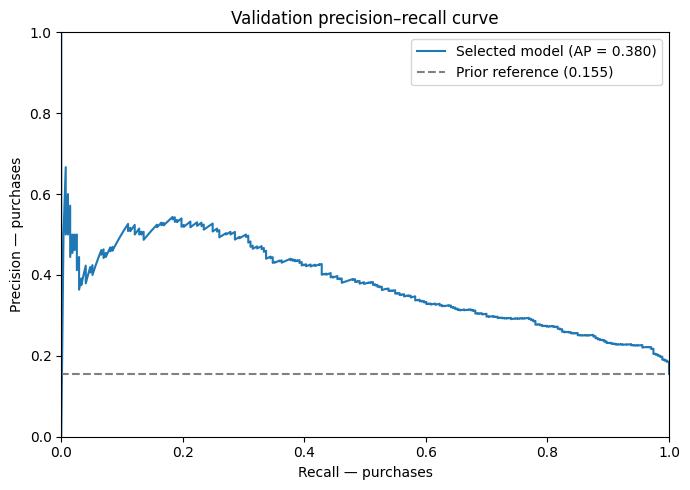

In [27]:
p_valid,r_valid,_ = precision_recall_curve(y_valid,valid_scores)
fig,ax=plt.subplots(figsize=(7,5))
ax.plot(r_valid,p_valid,label=f'Selected model (AP = {average_precision_score(y_valid,valid_scores):.3f})')
ax.axhline(y_valid.mean(),ls='--',color='gray',label=f'Prior reference ({y_valid.mean():.3f})')
ax.set(xlabel='Recall — purchases',ylabel='Precision — purchases',
       title='Validation precision–recall curve')
ax.set_xlim(0,1);ax.set_ylim(0,1);ax.legend()
plt.tight_layout()
plt.savefig(repo_root/'outputs'/'validation_pr_curve.png',dpi=145)
plt.show()

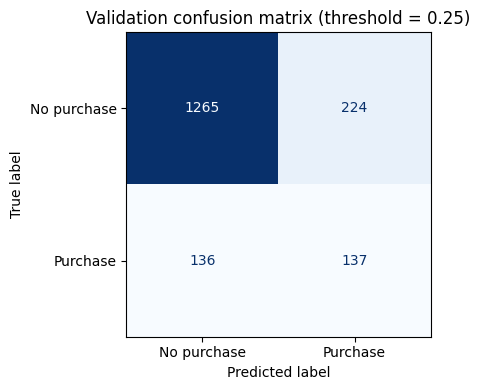

In [28]:
fig,ax=plt.subplots(figsize=(5,4))
valid_pred = (valid_scores >= threshold).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_valid,valid_pred),display_labels=['No purchase','Purchase']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title(f'Validation confusion matrix (threshold = {threshold:.2f})')
plt.tight_layout()
plt.savefig(repo_root/'outputs'/'validation_confusion_matrix.png',dpi=145)
plt.show()

### Freeze before opening the test results

I now freeze the model **already fitted on training data**, the selected feature set and the threshold. I will **not refit on validation**: that would change scores while retaining a threshold calibrated to a different fit. The test data have not been used to choose an estimator, feature or threshold. I will only run the test once for reporting.

In [29]:
frozen_pipeline = model
frozen_feature_columns = list(final_train_features.columns)
X_test_final = prepare_feature_frame(X_test,add_pace=use_pace)
assert list(X_test_final.columns) == frozen_feature_columns
assert 'PageValues' not in frozen_feature_columns
assert 'Revenue' not in frozen_feature_columns
print('Frozen model:',winner_name)
print('Engineered feature:',use_pace)
print('Threshold:',threshold)
print('Predictor count:',len(frozen_feature_columns))

Frozen model: RF_leaf5
Engineered feature: False
Threshold: 0.25
Predictor count: 16


In [30]:
# FINAL TEST: no more model/threshold tuning after this cell.
test_scores = frozen_pipeline.predict_proba(X_test_final)[:,1]
y_pred = (test_scores >= threshold).astype(int)
test_metrics = metrics_at_threshold(y_test,test_scores,threshold)
validation_metrics = metrics_at_threshold(y_valid,valid_scores,threshold)
final_comparison = pd.DataFrame([{'partition':'validation',**validation_metrics},
                                 {'partition':'test',**test_metrics}]).set_index('partition')
display(final_comparison.style.format(precision=4))
final_comparison.to_csv(repo_root/'outputs'/'frozen_evaluation.csv')
print('Test prevalence:',f'{y_test.mean():.3%}')
print('Test AP:',f'{test_metrics["AP"]:.4f}')

,AP,ROC_AUC,precision,recall,F1,accuracy,predicted_positive
partition,,,,,,,
validation,0.3801,0.7852,0.3795,0.5018,0.4322,0.7957,361
test,0.3913,0.7834,0.3541,0.4816,0.4081,0.7842,370


Test prevalence: 15.446%
Test AP: 0.3913


In [31]:
display(Markdown(
    f'**Frozen holdout results:** Test AP = **{test_metrics["AP"]:.3f}**, '
    f'ROC-AUC = {test_metrics["ROC_AUC"]:.3f}, '
    f'precision = {test_metrics["precision"]:.1%}, recall = {test_metrics["recall"]:.1%}, '
    f'F1 = {test_metrics["F1"]:.3f}, accuracy = {test_metrics["accuracy"]:.1%}. '
    'These reflect an offline holdout, not measured business uplift.'
))

**Frozen holdout results:** Test AP = **0.391**, ROC-AUC = 0.783, precision = 35.4%, recall = 48.2%, F1 = 0.408, accuracy = 78.4%. These reflect an offline holdout, not measured business uplift.

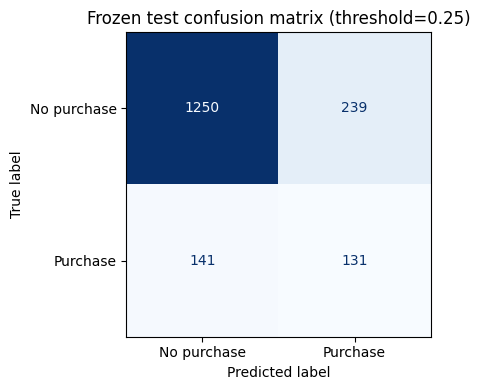

In [32]:
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(confusion_matrix(y_test,y_pred),display_labels=['No purchase','Purchase']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title(f'Frozen test confusion matrix (threshold={threshold:.2f})')
plt.tight_layout()
plt.savefig(repo_root/'outputs'/'test_confusion_matrix.png',dpi=145)
plt.show()

## D — Explainable AI and practical use

I will explain **prediction behavior**, not business causes. Permutation importance shuffles one original input column at a time and measures the drop in validation AP. It works for either final estimator **through the full pipeline**, and names stay tied to raw inputs. A correlation between columns can dilute individual importance values. I will also inspect error examples; I will not update the frozen model after looking at test errors.

,feature,AP_drop_mean,AP_drop_sd
9,Month,0.0445,0.0047
5,ProductRelated_Duration,0.0314,0.0123
7,ExitRates,0.0296,0.0169
14,VisitorType,0.0259,0.0073
13,TrafficType,0.0105,0.0074
10,OperatingSystems,0.0088,0.0043
1,Administrative_Duration,0.0070,0.0088
6,BounceRates,0.0069,0.0050
15,Weekend,0.0052,0.0016
4,ProductRelated,0.0014,0.0128


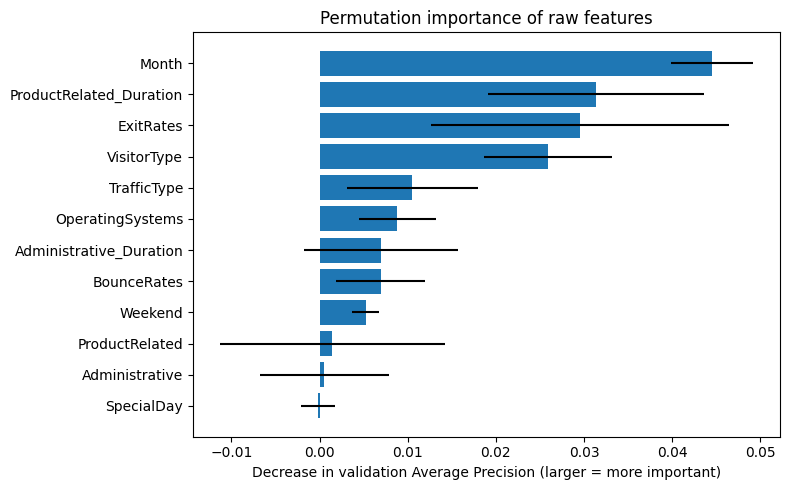

In [33]:
# Evaluation uses only validation; 3 repeats keep Colab runtime manageable.
importance = permutation_importance(
    frozen_pipeline, final_valid_features, y_valid,
    scoring='average_precision',n_repeats=3,random_state=random_state,n_jobs=1,
)
importance_table = pd.DataFrame({
    'feature':frozen_feature_columns,
    'AP_drop_mean':importance.importances_mean,
    'AP_drop_sd':importance.importances_std,
}).sort_values('AP_drop_mean',ascending=False)
display(importance_table.head(12).round(4))
importance_table.to_csv(repo_root/'outputs'/'permutation_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
top=importance_table.head(12).iloc[::-1]
ax.barh(top['feature'],top['AP_drop_mean'],xerr=top['AP_drop_sd'])
ax.set(xlabel='Decrease in validation Average Precision (larger = more important)',
       title='Permutation importance of raw features')
plt.tight_layout()
plt.savefig(repo_root/'outputs'/'permutation_importance.png',dpi=145)
plt.show()

In [34]:
# The raw-feature importance table above is the main global explanation.
display(Markdown(
    f'**Model explanation:** the highest measured validation AP decrease comes from '
    f'`{importance_table.iloc[0]["feature"]}` ({importance_table.iloc[0]["AP_drop_mean"]:.3f}). '
    'Permutation importance is association with model performance, not proof of causality.'
))

**Model explanation:** the highest measured validation AP decrease comes from `Month` (0.045). Permutation importance is association with model performance, not proof of causality.

In [35]:
# Coefficients are meaningful on the preprocessed scale only if logistic regression won.
if isinstance(frozen_pipeline.named_steps['model'], LogisticRegression):
    transformed_names = frozen_pipeline.named_steps['preprocess'].get_feature_names_out()
    coefficient_table = pd.DataFrame({
        'encoded_feature':transformed_names,
        'coefficient':frozen_pipeline.named_steps['model'].coef_[0],
    }).sort_values('coefficient')
    display(pd.concat([coefficient_table.head(8),coefficient_table.tail(8)]))
    print('Coefficient signs reflect standardized numeric or encoded-category contrasts, not causal effects.')
else:
    print('Forest selected. I use permutation importance instead of treating raw tree impurity values as causes.')

Forest selected. I use permutation importance instead of treating raw tree impurity values as causes.


In [36]:
# Inspect a few frozen test errors (no retuning).
review = X_test_final.copy()
review['actual_purchase'] = y_test.to_numpy()
review['purchase_score'] = test_scores
review['predicted_purchase'] = y_pred
false_positives = review.query('actual_purchase == 0 and predicted_purchase == 1')
false_negatives = review.query('actual_purchase == 1 and predicted_purchase == 0')
print('False positives:',len(false_positives),'| False negatives:',len(false_negatives))
show_cols = ['ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','VisitorType',
             'purchase_score','actual_purchase','predicted_purchase']
display(false_positives[show_cols].head(3))
display(false_negatives[show_cols].head(3))
print('FP = flagging a nonbuyer; FN = missing a buyer. Business costs are unknown.')

False positives: 239 | False negatives: 141


,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,VisitorType,purchase_score,actual_purchase,predicted_purchase
128,51,1873.216667,0.000000,0.007547,Returning_Visitor,0.334893,0,1
428,27,954.666667,0.000000,0.003846,Returning_Visitor,0.304479,0,1
502,79,2096.911364,0.003333,0.014009,Returning_Visitor,0.310495,0,1


,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,VisitorType,purchase_score,actual_purchase,predicted_purchase
220,14,643.000000,0.000000,0.013333,Returning_Visitor,0.133655,1,0
610,41,2720.671429,0.012963,0.033262,Returning_Visitor,0.199808,1,0
612,48,2309.732468,0.003846,0.014904,Returning_Visitor,0.207753,1,0


FP = flagging a nonbuyer; FN = missing a buyer. Business costs are unknown.


### One realistic raw-input prediction

I take an **observed holdout session**, remove the hidden target, and pass the raw input columns through the frozen pipeline. That is a demonstration of the input contract, not a claim of live early-session prediction. `predict_proba` produces a class-1 score; its numerical value is **not guaranteed calibrated**. Calibration would need separate analysis on appropriately partitioned data.

In [37]:
# EDITABLE: change values in raw_example (not its column names) and rerun this cell.
raw_example = X_test.iloc[[0]].copy()  # real observed input, no Revenue
example_features = prepare_feature_frame(raw_example,add_pace=use_pace)
example_features = example_features[frozen_feature_columns]
example_score = float(frozen_pipeline.predict_proba(example_features)[0,1])
example_decision = int(example_score >= threshold)
display(raw_example.T.rename(columns={raw_example.index[0]:'input value'}))
print(f'Class-1 (purchase) score: {example_score:.4f}')
print(f'Frozen threshold: {threshold:.2f}')
print('Decision:', 'predict purchase' if example_decision else 'predict no purchase')

,input value
Administrative,0
Administrative_Duration,0.0
Informational,0
Informational_Duration,0.0
ProductRelated,3
ProductRelated_Duration,738.0
BounceRates,0.0
ExitRates,0.022222
SpecialDay,0.4
Month,Feb


Class-1 (purchase) score: 0.1200
Frozen threshold: 0.25
Decision: predict no purchase


### Save useful artifacts and a compact experiment log

I save the entire fitted pipeline with its preprocessing, the frozen threshold, expected raw columns, and versions. I would only load this file from a trusted source: `joblib` deserialization is not safe for untrusted files. I record fitted settings as measured and keep the experiments that explain the decision.

In [38]:
experiment_log = validation_results[['candidate','reason','method','cv_AP_mean','AP']].copy()
experiment_log['decision'] = np.where(experiment_log['candidate'].eq(winner_name),
                                      'Primary candidate selected','Compared, not selected')
experiment_log.to_csv(repo_root/'outputs'/'experiment_log.csv',index=False)

bundle = {
    'pipeline':frozen_pipeline,
    'threshold':threshold,
    'feature_columns':frozen_feature_columns,
    'raw_feature_columns':primary_columns,
    'use_pace':use_pace,
    'selected_candidate':winner_name,
    'dataset_sha256':file_checksum,
    'source_used':source_used,
    'scikit_learn_version':sklearn.__version__,
    'pandas_version':pd.__version__,
}
model_path = repo_root/'models'/'shopsense_pipeline.joblib'
joblib.dump(bundle,model_path)
print('Saved model bundle:',model_path.name)

# A local round-trip verifies the inference contract after saving.
restored = joblib.load(model_path)
reloaded_input = prepare_feature_frame(raw_example,add_pace=restored['use_pace'])
reloaded_input = reloaded_input[restored['feature_columns']]
reloaded_score = float(restored['pipeline'].predict_proba(reloaded_input)[0,1])
assert np.isclose(reloaded_score,example_score)
print('Saved-model round trip: PASS')

Saved model bundle: shopsense_pipeline.joblib
Saved-model round trip: PASS


In [39]:
report = {
    'data': {'filename':dataset_path.name,'source':source_used,'sha256':file_checksum,
             'rows':len(df),'columns':len(df.columns),'positive_sessions':int(df['Revenue'].sum())},
    'split':split_report.to_dict(orient='records'),
    'selected_model':winner_name,
    'use_engineered_feature':use_pace,
    'page_values_in_headline_model':False,
    'threshold':threshold,
    'validation':validation_metrics,
    'test':test_metrics,
    'libraries':{'python':platform.python_version(),'pandas':pd.__version__,
                 'scikit-learn':sklearn.__version__,'numpy':np.__version__},
}
with open(repo_root/'outputs'/'summary.json','w') as handle:
    json.dump(report,handle,indent=2,default=float)
print('Saved outputs/summary.json')
print('Actual test AP:',f'{test_metrics["AP"]:.4f}')
print('Actual test precision/recall/F1:',*(f'{test_metrics[k]:.4f}' for k in ['precision','recall','F1']))

Saved outputs/summary.json
Actual test AP: 0.3913
Actual test precision/recall/F1: 0.3541 0.4816 0.4081


## What I can and cannot conclude

I selected from a **small named set** of candidates using validation AP, tested one engineered feature, and examined a clearly separated PageValues sensitivity analysis. The final threshold was chosen on validation F1, then applied once to the untouched test partition. All displayed numbers are computed by the cells above.

**Limits:** This is an old one-year, session-level dataset without timestamps sufficient for temporal validation. Some features are complete-session summaries or externally computed analytics; their true availability at decision time is unverified. An offline classification score is not a measured sales uplift. The dataset has no pricing or intervention-cost information, and no proof of probability calibration. I would require timestamped logging, a feature-provenance audit, drift assessment, calibration checks, and a prospective evaluation before deploying this.

**My next step:** if those checks are possible, I can validate at a defined point during a shopping session. Until then this stays an offline model-comparison portfolio project.

**Reproducibility:** `random_state`, models, preprocessing and threshold grid are editable above. Changing a dataset path or random seed means **rerun all**. Changing features means **rerun from splitting/preprocessing**, and changing models means **rerun from model definitions**. Threshold changes require rerunning threshold selection, test reporting, explanations and saved inference artifacts; test data must not be used for choosing a new threshold.